# 0 · Wheel wavelet states — test on two sessions

Pipeline being tested (nothing saved, nothing segmented for real):
1. 200 Hz wheel velocity → log Morlet amplitudes, 0.5–16 Hz in half-octaves, **rightward and leftward parts separately** (a plain amplitude can't tell a left from a right turn).
2. **No per-session normalisation**: features stay in log(rad/s). No feature scaling either — all features share units.
3. Uniform subsample of frames from each session → k-means (n_init=10) → label every frame.

Test data: one mouse, its first and last training session. The questions: does the feature space separate still / direction / speed, how many states does it support, and what do the states look like at 5 ms resolution.

*Archived (2026-11-05): an approach that was not taken forward. Kept for reference; outputs are from the original run.*

In [1]:
import sys; sys.path.insert(0, '..')   # archived: the modules live one folder up
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import wheel_states as ws

MOUSE = 'CSHL049'
N_SUB = 20000          # frames per session in the training subsample
KS = [4, 8, 16, 24, 32, 48, 64]
rng = np.random.default_rng(0)

man = ws.manifest().query('mouse == @MOUSE').sort_values('session_index')
sess = man.iloc[[0, -1]]
names = ws.feature_names()
data = {}
for _, r in sess.iterrows():
    dm, trials, X, valid = ws.session_features(r.eid, MOUSE)
    data[r.session_index] = dict(dm=dm, trials=trials, X=X, valid=valid)
    print(f'session {r.session_index}: {len(dm)/ws.FS/60:.0f} min, {len(trials)} trials, '
          f'{(~valid).sum()} frames masked near encoder jumps')

session 1: 55 min, 203 trials, 805 frames masked near encoder jumps


session 15: 63 min, 826 trials, 402 frames masked near encoder jumps


## Feature distributions: early vs late, no normalisation

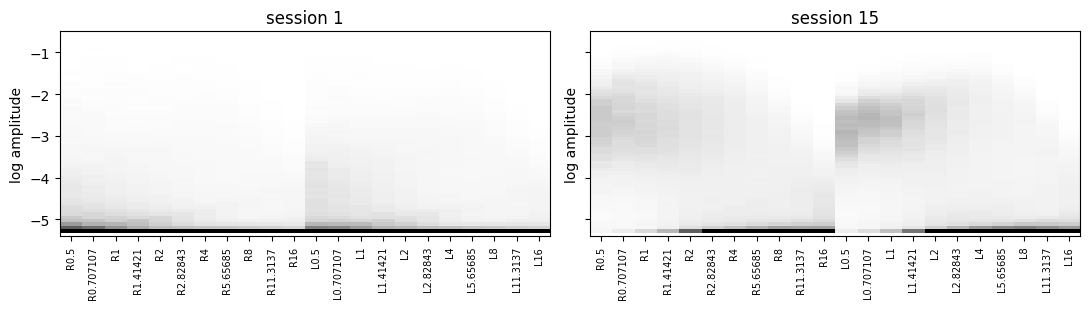

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (k, d) in zip(axs, data.items()):
    X = d['X'][d['valid']]
    ax.imshow(np.array([np.histogram(X[:, j], bins=60, range=(-5.4, -0.5), density=True)[0]
                        for j in range(X.shape[1])]).T, aspect='auto', origin='lower', cmap='Greys',
              extent=[-.5, X.shape[1] - .5, -5.4, -0.5], vmax=1.5)
    ax.set_xticks(range(len(names)), names, rotation=90, fontsize=7)
    ax.set_title(f'session {k}'); ax.set_ylabel('log amplitude')
plt.tight_layout()

## Number of states: held-out cost and seed/subsample stability

In [3]:
def subsample(d, n, rng):
    idx = np.flatnonzero(d['valid'])
    return d['X'][rng.choice(idx, n, replace=False)]

train = np.concatenate([subsample(d, N_SUB, rng) for d in data.values()])
test = np.concatenate([subsample(d, N_SUB, rng) for d in data.values()])
train2 = np.concatenate([subsample(d, N_SUB, rng) for d in data.values()])
allX = np.concatenate([d['X'][d['valid']] for d in data.values()])
evalX = allX[rng.choice(len(allX), 200000, replace=False)]

rows, models = [], {}
for K in KS:
    km = KMeans(K, n_init=10, random_state=0).fit(train)
    km2 = KMeans(K, n_init=10, random_state=1).fit(train2)
    occ = np.bincount(km.predict(evalX), minlength=K) / len(evalX)
    rows.append(dict(K=K, heldout_cost=-km.score(test) / len(test),
                     ARI_other_subsample=adjusted_rand_score(km.predict(evalX), km2.predict(evalX)),
                     smallest_state=occ.min(), largest_state=occ.max()))
    models[K] = km
sweep = pd.DataFrame(rows).set_index('K'); sweep.round(3)

,heldout_cost,ARI_other_subsample,smallest_state,largest_state
K,,,,
4,8.192,0.985,0.150,0.386
8,5.684,0.976,0.069,0.311
16,4.211,0.861,0.033,0.261
24,3.652,0.883,0.018,0.226
32,3.326,0.807,0.013,0.239
48,2.945,0.903,0.007,0.219
64,2.739,0.796,0.005,0.206


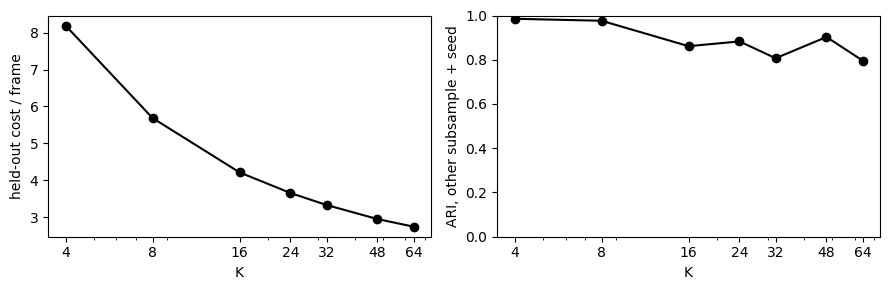

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
axs[0].plot(sweep.index, sweep.heldout_cost, 'o-', c='k'); axs[0].set(xlabel='K', ylabel='held-out cost / frame', xscale='log')
axs[1].plot(sweep.index, sweep.ARI_other_subsample, 'o-', c='k'); axs[1].set(xlabel='K', ylabel='ARI, other subsample + seed', xscale='log', ylim=(0, 1))
for ax in axs: ax.set_xticks(KS, KS)
plt.tight_layout()

## What the states are (K = 32)

In [5]:
K = 32
km = models[K]
for d in data.values():
    d['state'] = np.where(d['valid'], km.predict(d['X']), -1)

# order states by overall amplitude (vigor), split by direction
cen = km.cluster_centers_
nf = len(ws.FREQS)
right, left = cen[:, :nf], cen[:, nf:]
vigor = np.logaddexp(right, left).mean(1)
order = np.argsort(vigor)

prof = []
for s in range(K):
    v = np.concatenate([d['dm']['velocity'].values[d['state'] == s] for d in data.values()])
    runs = []
    for d in data.values():
        st = d['state']; edges = np.flatnonzero(np.diff(st)) + 1
        lens = np.diff(np.r_[0, edges, len(st)]); lab = st[np.r_[0, edges]]
        runs.append(lens[lab == s])
    runs = np.concatenate(runs) * 1000 / ws.FS
    prof.append(dict(state=s, occ_first=(data[sess.session_index.iloc[0]]['state'] == s).mean(),
                     occ_last=(data[sess.session_index.iloc[1]]['state'] == s).mean(),
                     median_vel=np.median(v), median_speed=np.median(np.abs(v)),
                     frac_right=(v > 0).mean(), median_dwell_ms=np.median(runs)))
prof = pd.DataFrame(prof).set_index('state').loc[order]
prof.round(3)

,occ_first,occ_last,median_vel,median_speed,frac_right,median_dwell_ms
state,,,,,,
0,0.478,0.031,-0.000,0.001,0.456,4135.0
13,0.111,0.014,0.000,0.002,0.472,920.0
23,0.055,0.020,0.000,0.002,0.577,750.0
30,0.021,0.045,0.000,0.002,0.433,472.5
11,0.047,0.002,-0.011,0.034,0.386,240.0
2,0.010,0.045,0.000,0.000,0.485,470.0
8,0.031,0.020,-0.000,0.004,0.472,350.0
5,0.002,0.067,-0.000,0.002,0.418,362.5
7,0.017,0.028,0.004,0.014,0.640,200.0


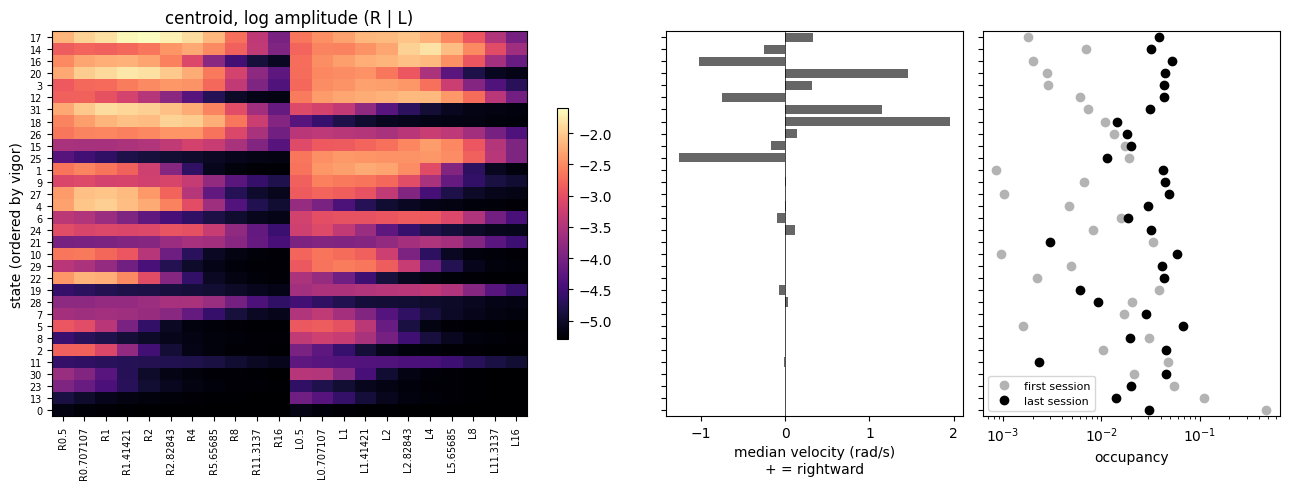

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(13, 5), gridspec_kw=dict(width_ratios=[2, 1, 1]), sharey=True)
y = np.arange(K)
im = axs[0].imshow(cen[order], aspect='auto', cmap='magma', origin='lower')
axs[0].set_xticks(range(len(names)), names, rotation=90, fontsize=7); axs[0].set_ylabel('state (ordered by vigor)')
axs[0].set_yticks(y, order, fontsize=7); axs[0].set_title('centroid, log amplitude (R | L)')
plt.colorbar(im, ax=axs[0], shrink=.6)
axs[1].barh(y, prof.median_vel, color='0.4'); axs[1].axvline(0, c='k', lw=.5); axs[1].set(xlabel='median velocity (rad/s)\n+ = rightward')
axs[2].plot(prof.occ_first, y, 'o', c='0.7', label='first session'); axs[2].plot(prof.occ_last, y, 'o', c='k', label='last session')
axs[2].set(xlabel='occupancy', xscale='log'); axs[2].legend(fontsize=8)
plt.tight_layout()

## Example: 20 s of the last session, velocity coloured by state

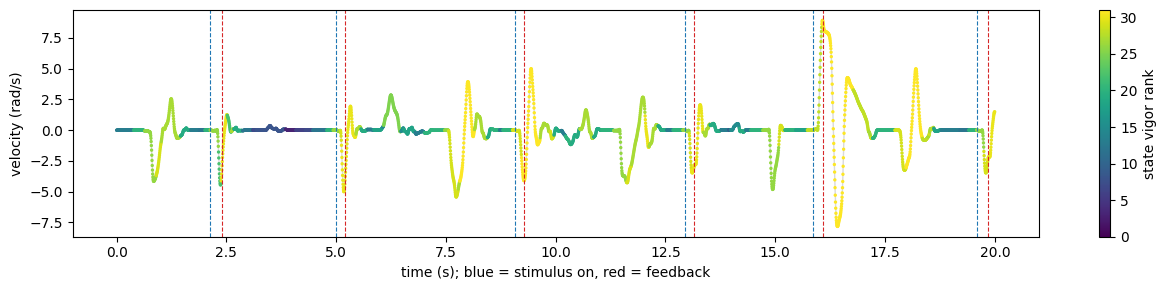

In [7]:
d = data[sess.session_index.iloc[1]]
tr = d['trials']; t0 = tr.stimOn_times.iloc[200] - 5
sel = (d['dm'].times > t0) & (d['dm'].times < t0 + 20)
t, v, st = d['dm'].times[sel].values - t0, d['dm'].velocity[sel].values, d['state'][sel]
rank = np.empty(K, int); rank[order] = np.arange(K)
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(t, v, c='0.85', lw=1, zorder=0)
sc = ax.scatter(t, v, c=rank[st], cmap='viridis', s=2, vmin=0, vmax=K - 1)
for col, c in [('stimOn_times', 'tab:blue'), ('feedback_times', 'tab:red')]:
    for e in tr[col].values:
        if 0 < e - t0 < 20: ax.axvline(e - t0, c=c, lw=.8, ls='--')
ax.set(xlabel='time (s); blue = stimulus on, red = feedback', ylabel='velocity (rad/s)')
plt.colorbar(sc, ax=ax, label='state vigor rank'); plt.tight_layout()

## Variants: lowest band, and stillness as its own state

At K = 32 about half the states are still (median speed ≈ 0): 64 % of frames are still, and the log stretches tiny residual amplitudes, so k-means spends states on flavours of stillness. Here: (a) drop the slowest bands (their windows are ±1.6 s at 0.5 Hz, ±0.8 s at 1 Hz), (b) call |v| < 0.1 rad/s (epoch_structure's MOVE_THRESH) "still" and cluster only moving frames.

In [8]:
rows = []
for lo in [0.5, 1.0, 2.0]:
    cols = [i for i, n in enumerate(names) if float(n[1:]) >= lo]
    for still_thr in [None, 0.1]:
        tr1, tr2, ev = [], [], []
        for d in data.values():
            v = d['dm']['velocity'].values
            ok = d['valid'] & (np.abs(v) >= still_thr) if still_thr else d['valid']
            idx = np.flatnonzero(ok)
            tr1.append(d['X'][rng.choice(idx, N_SUB, replace=False)][:, cols])
            tr2.append(d['X'][rng.choice(idx, N_SUB, replace=False)][:, cols])
            ev.append((v[ok], d['X'][ok][:, cols]))
        km1 = KMeans(32, n_init=10, random_state=0).fit(np.concatenate(tr1))
        km2 = KMeans(32, n_init=10, random_state=1).fit(np.concatenate(tr2))
        Xe = np.concatenate([e[1] for e in ev]); ve = np.concatenate([e[0] for e in ev])
        sid = np.concatenate([np.full(len(e[0]), i) for i, e in enumerate(ev)])
        sel = rng.choice(len(Xe), 200000, replace=False)
        lab = km1.predict(Xe[sel])
        med = np.array([np.median(np.abs(ve[sel][lab == k])) for k in range(32)])
        p_last = np.array([(sid[sel][lab == k] == 1).mean() for k in range(32)])
        rows.append(dict(lowest_band_Hz=lo, still_state=still_thr is not None,
                         ARI=adjusted_rand_score(lab, km2.predict(Xe[sel])),
                         n_still_like_states=(med < 0.05).sum(),
                         n_states_90pct_one_session=((p_last > .9) | (p_last < .1)).sum()))
pd.DataFrame(rows).round(2)

,lowest_band_Hz,still_state,ARI,n_still_like_states,n_states_90pct_one_session
0,0.5,False,0.84,15,16
1,0.5,True,0.64,0,12
2,1.0,False,0.92,16,13
3,1.0,True,0.60,0,10
4,2.0,False,0.87,13,12
5,2.0,True,0.59,0,7
